In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline

In [2]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'car data.csv', 'OASIS INFOBYTE — Task List.pdf', 'Task_1_Iris_Flower_Classification.ipynb', 'Task_2_Unemployment_Analysis.ipynb', 'Task_3_Car_Price_Prediction.ipynb', 'Unemployment in India.csv']


In [3]:
# Load the car dataset

df = pd.read_csv("car data.csv")

# Display first 5 rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (4340, 8)


In [5]:
print("Columns:")
print(df.columns.tolist())

Columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [6]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check column data types and non-null values
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
df.describe(include="all")

Dataset Shape: (4340, 8)
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate Rows: 763


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
count,4340,4340.000000,4.340000e+03,4340.000000,4340,4340,4340,4340
unique,1491,NaN,NaN,NaN,5,3,2,5
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner
freq,69,NaN,NaN,NaN,2153,3244,3892,2832
mean,NaN,2013.090783,5.041273e+05,66215.777419,NaN,NaN,NaN,NaN
std,NaN,4.215344,5.785487e+05,46644.102194,NaN,NaN,NaN,NaN
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2011.000000,2.087498e+05,35000.000000,NaN,NaN,NaN,NaN
50%,NaN,2014.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN


In [7]:
# Create a copy of the original dataset
df = df.copy()

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Clean categorical columns
categorical_cols = [
    "name",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

for col in categorical_cols:
    df[col] = df[col].astype("string").str.strip().str.lower()

# Convert numeric columns to numeric data types
numeric_cols = [
    "year",
    "selling_price",
    "km_driven"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing essential values
df = df.dropna(
    subset=["name", "year", "selling_price", "km_driven"]
).copy()

# Remove invalid records
df = df[
    (df["selling_price"] > 0) &
    (df["year"] > 1900) &
    (df["km_driven"] >= 0)
].copy()

# Check cleaned data
print("Shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

df.head()

Shape after cleaning: (3577, 8)

Missing values after cleaning:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,maruti 800 ac,2007,60000,70000,petrol,individual,manual,first owner
1,maruti wagon r lxi minor,2007,135000,50000,petrol,individual,manual,first owner
2,hyundai verna 1.6 sx,2012,600000,100000,diesel,individual,manual,first owner
3,datsun redigo t option,2017,250000,46000,petrol,individual,manual,first owner
4,honda amaze vx i-dtec,2014,450000,141000,diesel,individual,manual,second owner


In [8]:
# Calculate car age using the current year
current_year = pd.Timestamp.today().year

df["car_age"] = current_year - df["year"]

# Extract the first word of the car name as the brand
df["brand"] = df["name"].str.split().str[0]

# Display the new features
df[["name", "year", "car_age", "brand", "selling_price"]].head(10)

,name,year,car_age,brand,selling_price
0,maruti 800 ac,2007,19,maruti,60000
1,maruti wagon r lxi minor,2007,19,maruti,135000
2,hyundai verna 1.6 sx,2012,14,hyundai,600000
3,datsun redigo t option,2017,9,datsun,250000
4,honda amaze vx i-dtec,2014,12,honda,450000
5,maruti alto lx bsiii,2007,19,maruti,140000
6,hyundai xcent 1.2 kappa s,2016,10,hyundai,550000
7,tata indigo grand petrol,2014,12,tata,240000
8,hyundai creta 1.6 vtvt s,2015,11,hyundai,850000
9,maruti celerio green vxi,2017,9,maruti,365000


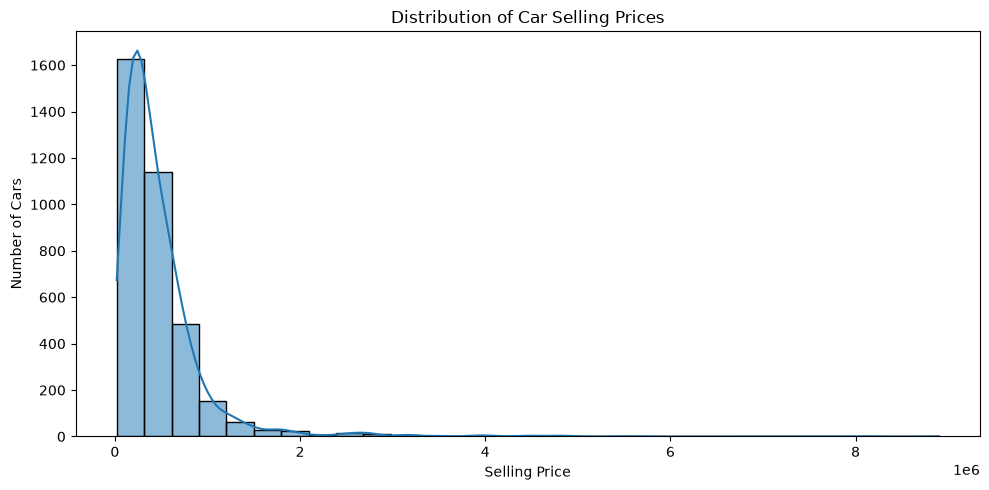

In [9]:
# Plot the distribution of selling prices

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="selling_price",
    bins=30,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

Observation:
The selling price distribution shows how car prices are spread across the dataset. A concentration of observations at lower prices with a long right tail would indicate that most cars are relatively affordable, while a few cars have much higher selling prices.

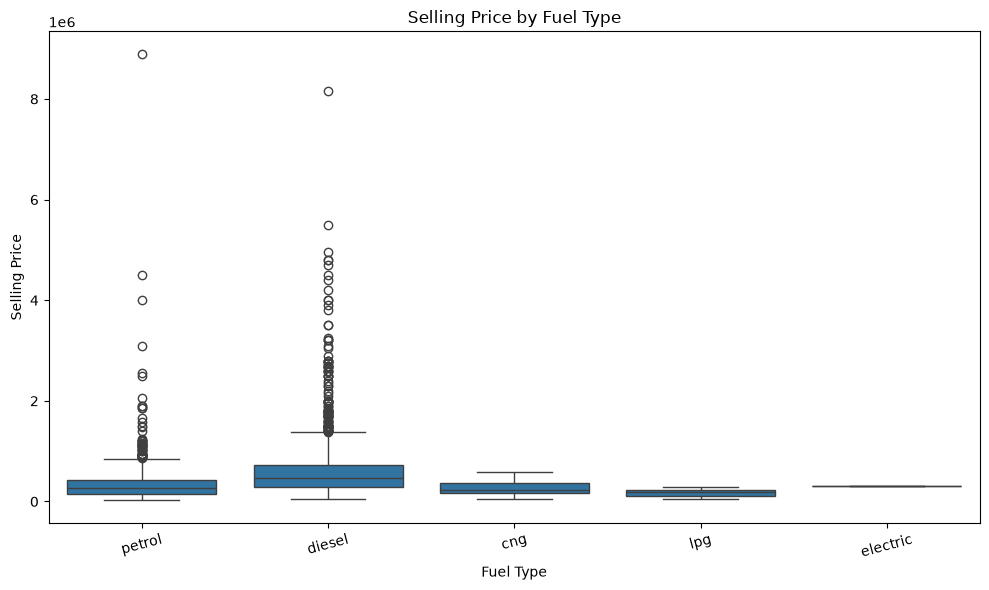

In [10]:
# Compare selling prices across fuel types

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="fuel",
    y="selling_price"
)

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Observation:
The box plot compares the median selling price and price variation across fuel types. Differences may reflect variations in vehicle age, brand, and model, so fuel type alone should not be interpreted as the cause of price differences.

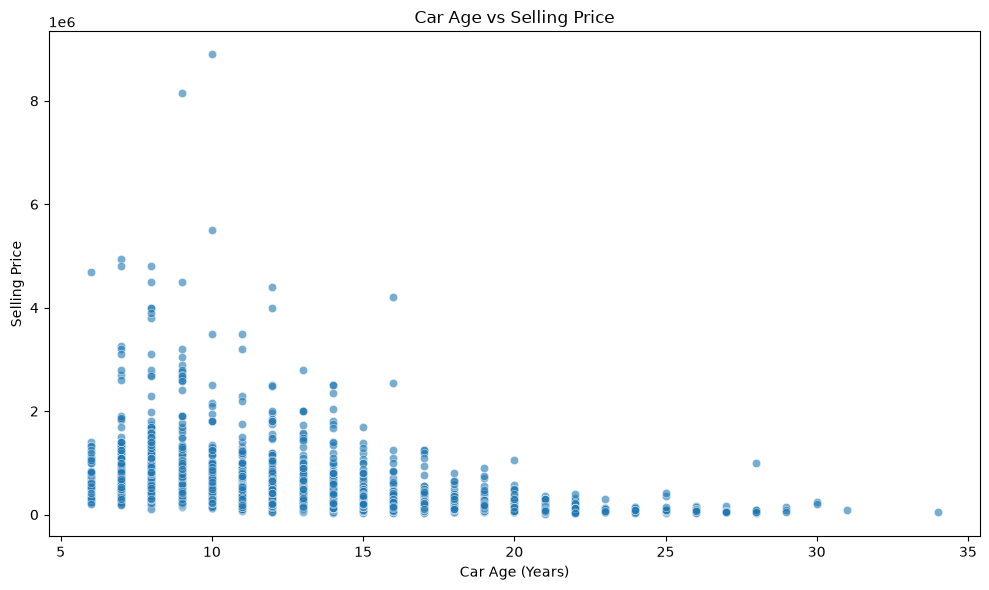

In [11]:
# Examine the relationship between car age and selling price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.6
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

Observation:
The scatter plot helps identify the relationship between car age and selling price. If prices generally decrease as car age increases, this suggests a negative relationship between age and selling price.

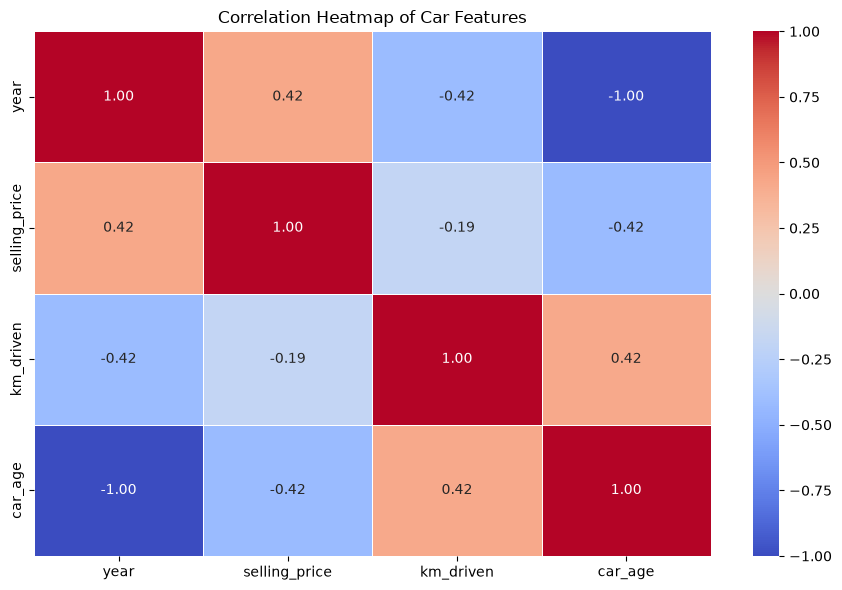

In [12]:
# Select numerical columns for correlation analysis

numeric_features = [
    "year",
    "selling_price",
    "km_driven",
    "car_age"
]

correlation_matrix = df[numeric_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Car Features")
plt.tight_layout()
plt.show()

Observation:
The correlation heatmap shows the strength and direction of relationships between numerical features. Car age and year are inversely related because older cars have earlier manufacturing years. Correlation with selling price helps identify potentially useful features, but correlation does not prove causation.

In [13]:
# Define input features and target variable

features = [
    "brand",
    "car_age",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

X = df[features].copy()
y = df["selling_price"].copy()

# Identify categorical and numerical features
categorical_features = [
    "brand",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

numerical_features = [
    "car_age",
    "km_driven"
]

# Create a preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Features:", features)
print("Target: selling_price")
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Features: ['brand', 'car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
Target: selling_price
Categorical features: ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
Numerical features: ['car_age', 'km_driven']


In [14]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2861, 7)
Testing features: (716, 7)
Training target: (2861,)
Testing target: (716,)


In [15]:
# Define three regression models

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

# Train each model and store its predictions
trained_models = {}
predictions = {}

for model_name, model in models.items():

    # Combine preprocessing and regression model
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict car selling prices
    y_pred = pipeline.predict(X_test)

    # Save trained model and predictions
    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred

    print(f"{model_name} trained successfully!")

print("\nAll models have been trained.")

Linear Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!

All models have been trained.


In [16]:
# Evaluate all trained regression models

results = []

for model_name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create a comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("Model Performance Comparison:")
display(results_df.round(3))

Model Performance Comparison:


,Model,MAE,RMSE,R2 Score
0,Random Forest,158737.181,366620.094,0.583
1,Gradient Boosting,157041.969,377775.860,0.557
2,Linear Regression,206368.402,431734.103,0.421


In [17]:
# Select the model with the highest R2 score

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("\nBest Model Metrics:")
print(results_df.iloc[0])

Best Model: Random Forest

Best Model Metrics:
Model       Random Forest
MAE         158737.181496
RMSE        366620.094193
R2 Score          0.58275
Name: 0, dtype: object


In [18]:
# Get the trained preprocessing step and regression model

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_regressor = best_model.named_steps["model"]

# Get feature names after One-Hot Encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract importance or coefficient values
if hasattr(fitted_regressor, "feature_importances_"):
    importance_values = fitted_regressor.feature_importances_

elif hasattr(fitted_regressor, "coef_"):
    # Absolute coefficients indicate magnitude, not direction
    importance_values = np.abs(fitted_regressor.coef_)

else:
    raise ValueError("This model does not provide feature importance or coefficients.")

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
display(importance_df.head(15).round(4))

,Feature,Importance
41,numerical__car_age,0.2238
42,numerical__km_driven,0.1317
34,categorical__transmission_automatic,0.1275
35,categorical__transmission_manual,0.1165
28,categorical__fuel_diesel,0.0775
1,categorical__brand_audi,0.0526
13,categorical__brand_land,0.0403
24,categorical__brand_toyota,0.0370
30,categorical__fuel_petrol,0.0359
2,categorical__brand_bmw,0.0136


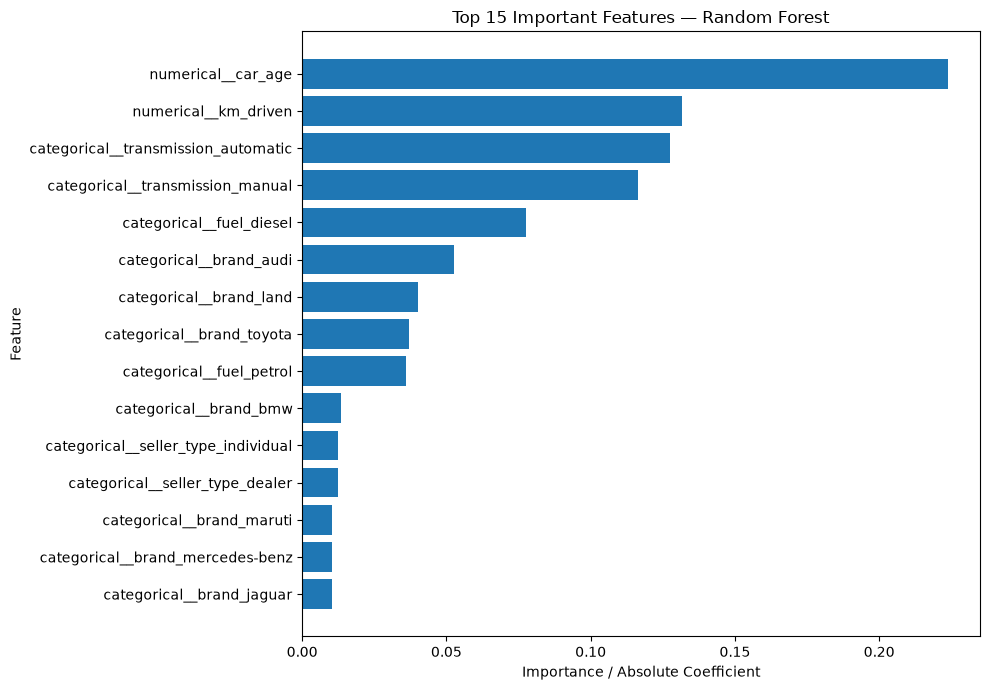

In [19]:
# Plot the top 15 important features

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title(f"Top 15 Important Features — {best_model_name}")
plt.xlabel("Importance / Absolute Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Observation:
The feature importance chart identifies which input features contribute most to the selected model's predictions. For tree-based models, importance values indicate relative contribution. For Linear Regression, absolute coefficients show coefficient magnitude, not true feature importance, and can be affected by feature scaling and encoding.

In [20]:
# Predict prices using the best model

best_predictions = best_model.predict(X_test)

# Compare actual and predicted prices
comparison_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": best_predictions
})

comparison_df["Absolute Error"] = abs(
    comparison_df["Actual Price"] -
    comparison_df["Predicted Price"]
)

display(comparison_df.head(10).round(2))

,Actual Price,Predicted Price,Absolute Error
0,270000,568614.04,298614.04
1,525000,466447.43,58552.57
2,990000,1464919.92,474919.92
3,3800000,2523829.97,1276170.03
4,229999,240700.00,10701.00
5,325000,351654.99,26654.99
6,210000,181033.33,28966.67
7,500000,681109.98,181109.98
8,790000,878759.06,88759.06
9,360000,463110.00,103110.00


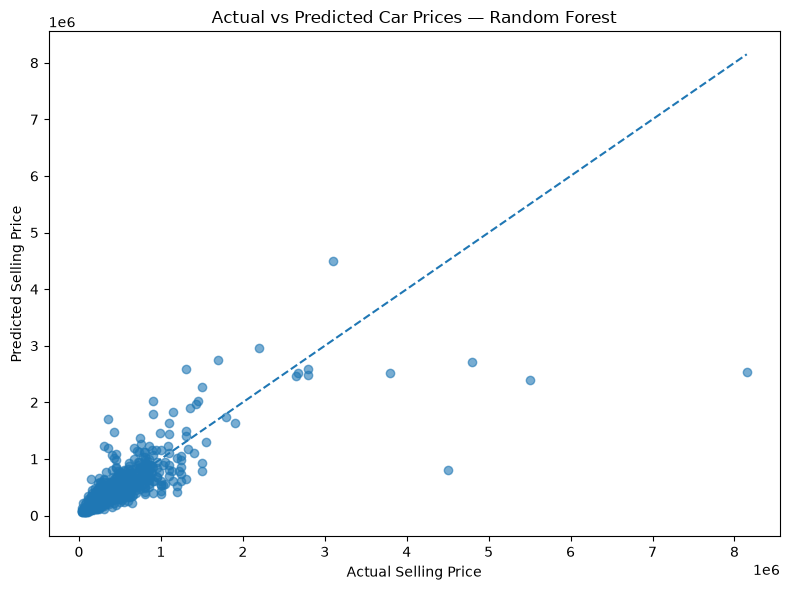

In [21]:
# Plot actual prices against predicted prices

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

# Reference line for perfect predictions
min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Car Prices — {best_model_name}")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.tight_layout()
plt.show()

Observation:
Points closer to the diagonal reference line indicate more accurate predictions. Points farther away represent larger prediction errors. The graph helps assess how well the selected model predicts car selling prices.

In [22]:
# Create a sample car with the same input columns used for training

new_car = pd.DataFrame([{
    "brand": "maruti",
    "car_age": 5,
    "km_driven": 40000,
    "fuel": "petrol",
    "seller_type": "individual",
    "transmission": "manual",
    "owner": "first owner"
}])

# Predict the selling price
predicted_price = best_model.predict(new_car)[0]

print(f"Selected Model: {best_model_name}")
print(f"Predicted Selling Price: {predicted_price:,.2f}")

Selected Model: Random Forest
Predicted Selling Price: 426,981.19
